# 1. Chuẩn bị môi trường

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

# 2. Đọc dataset FIFA

In [2]:
df = pd.read_csv("players_20.csv")

df.head()

,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,...,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,...,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,...,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,...,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,...,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


In [3]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

Số dòng: 18278
Số cột: 104


In [4]:
df.columns.tolist()

['sofifa_id',
 'player_url',
 'short_name',
 'long_name',
 'age',
 'dob',
 'height_cm',
 'weight_kg',
 'nationality',
 'club',
 'overall',
 'potential',
 'value_eur',
 'wage_eur',
 'player_positions',
 'preferred_foot',
 'international_reputation',
 'weak_foot',
 'skill_moves',
 'work_rate',
 'body_type',
 'real_face',
 'release_clause_eur',
 'player_tags',
 'team_position',
 'team_jersey_number',
 'loaned_from',
 'joined',
 'contract_valid_until',
 'nation_position',
 'nation_jersey_number',
 'pace',
 'shooting',
 'passing',
 'dribbling',
 'defending',
 'physic',
 'gk_diving',
 'gk_handling',
 'gk_kicking',
 'gk_reflexes',
 'gk_speed',
 'gk_positioning',
 'player_traits',
 'attacking_crossing',
 'attacking_finishing',
 'attacking_heading_accuracy',
 'attacking_short_passing',
 'attacking_volleys',
 'skill_dribbling',
 'skill_curve',
 'skill_fk_accuracy',
 'skill_long_passing',
 'skill_ball_control',
 'movement_acceleration',
 'movement_sprint_speed',
 'movement_agility',
 'movement_re

# 3. EDA và kiểm tra chất lượng dữ liệu

## 3.1. Kiểu dữ liệu

In [5]:
for i, (column, dtype) in enumerate(df.dtypes.items(), start=1):
    print(f"{i:3}. {column:30} {dtype}")

  1. sofifa_id                      int64
  2. player_url                     object
  3. short_name                     object
  4. long_name                      object
  5. age                            int64
  6. dob                            object
  7. height_cm                      int64
  8. weight_kg                      int64
  9. nationality                    object
 10. club                           object
 11. overall                        int64
 12. potential                      int64
 13. value_eur                      int64
 14. wage_eur                       int64
 15. player_positions               object
 16. preferred_foot                 object
 17. international_reputation       int64
 18. weak_foot                      int64
 19. skill_moves                    int64
 20. work_rate                      object
 21. body_type                      object
 22. real_face                      object
 23. release_clause_eur             float64
 24. player_tags     

## 3.2. Missing value

In [6]:
missing = df.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

loaned_from             17230
nation_position         17152
nation_jersey_number    17152
player_tags             16779
gk_diving               16242
gk_reflexes             16242
gk_kicking              16242
gk_handling             16242
gk_speed                16242
gk_positioning          16242
player_traits           10712
dribbling                2036
defending                2036
shooting                 2036
pace                     2036
passing                  2036
ram                      2036
lm                       2036
lcm                      2036
cm                       2036
rcm                      2036
physic                   2036
ls                       2036
st                       2036
rs                       2036
lw                       2036
lf                       2036
cf                       2036
rf                       2036
rw                       2036
lam                      2036
cam                      2036
cdm                      2036
rdm       

## 3.3. Duplicate

In [7]:
print("Số dòng trùng:", df.duplicated().sum())

Số dòng trùng: 0


# 4. Lọc bỏ thủ môn

In [8]:
df["player_positions"].head()

0    RW, CF, ST
1        ST, LW
2       LW, CAM
3            GK
4        LW, CF
Name: player_positions, dtype: object

In [9]:
df_cluster = df[
    ~df["player_positions"].str.contains("GK", na=False)
].copy()

print("Trước khi lọc:", len(df))
print("Sau khi lọc:", len(df_cluster))

Trước khi lọc: 18278
Sau khi lọc: 16242


# 5. Chọn feature cho clustering

In [10]:
features = [
    # Attacking
    "attacking_crossing",
    "attacking_finishing",
    "attacking_heading_accuracy",
    "attacking_short_passing",
    "attacking_volleys",

    # Skill
    "skill_dribbling",
    "skill_curve",
    "skill_fk_accuracy",
    "skill_long_passing",
    "skill_ball_control",

    # Movement
    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "movement_balance",

    # Physical / Power
    "power_shot_power",
    "power_jumping",
    "power_stamina",
    "power_strength",
    "power_long_shots",

    # Mentality
    "mentality_aggression",
    "mentality_positioning",
    "mentality_vision",
    "mentality_penalties",
    "mentality_composure",

    # Defending
    "defending_marking",
    "defending_standing_tackle",
    "defending_sliding_tackle",

    # General skills
    "weak_foot",
    "skill_moves"
]

print("Số lượng feature:", len(features))

Số lượng feature: 30


Bài toán tập trung vào việc phân loại các kiểu cầu thủ. Vì vậy, các feature được lựa chọn chủ yếu thuộc các nhóm kỹ năng tấn công, kỹ thuật xử lý bóng, di chuyển, thể chất, mentality và phòng ngự. Những biến này phản ánh trực tiếp khả năng và đặc điểm thi đấu của cầu thủ. Ngược lại, các biến định danh như tên, ID, URL, câu lạc bộ và quốc tịch không được sử dụng làm input clustering. Các biến overall, potential, value_eur và wage_eur cũng được loại bỏ vì có thể khiến cluster phản ánh mức độ đánh giá hoặc giá trị thị trường thay vì phong cách thi đấu. Việc lựa chọn này phù hợp với yêu cầu của đề bài.

# 6. Xử lý missing value của feature

In [11]:
df_cluster[features].isnull().sum()

X = df_cluster[features].copy()

X = X.fillna(X.median())

print("Tổng missing:", X.isnull().sum().sum())

Tổng missing: 0


# 7. Scale dữ liệu

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [13]:
print("Shape:", X_scaled.shape)

Shape: (16242, 30)


# 8. K-Means

## 8.1. chạy K-Means với k=3 đến 10 

In [14]:
k_values = range(3, 11)

inertias = []
silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

results_kmeans = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouette_scores
})

display(results_kmeans)

,k,inertia,silhouette
0,3,308491.808491,0.187511
1,4,278811.507971,0.164974
2,5,262274.145683,0.143865
3,6,248054.665421,0.140257
4,7,236331.814686,0.138878
5,8,225486.476559,0.137249
6,9,218049.666744,0.125697
7,10,212383.507077,0.121719


## 8.2. Vẽ Elbow Curve

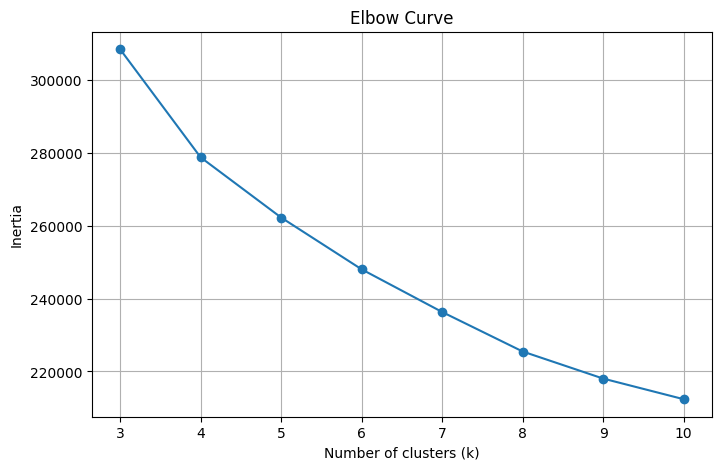

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Curve")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

## 8.3. Vẽ Silhouette Curve

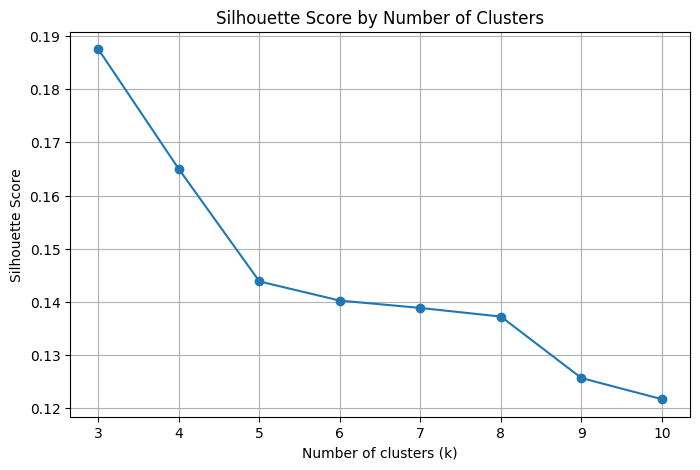

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

## 8.4. chọn K =5


K=5 được lựa chọn dựa trên sự kết hợp giữa Elbow Curve, Silhouette Score và khả năng diễn giải các cụm. Silhouette Score cao nhất tại K=3 và giảm dần khi số cụm tăng, cho thấy việc chia dữ liệu thành ít cụm hơn có mức độ tách biệt tốt hơn. Tuy nhiên, từ khoảng K=5–6 trở đi, mức giảm inertia khi tăng thêm số cụm bắt đầu nhỏ dần. K=5 cung cấp sự cân bằng giữa mức độ giảm biến thiên trong cụm và khả năng phân biệt các nhóm cầu thủ. Vì vậy, K=5 được giữ làm số cluster cuối cùng dựa trên cả metric định lượng và khả năng diễn giải về mặt chuyên môn.

## 8.5. Train K-Means cuối cùng với K = 5

In [17]:
kmeans_final = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train model và lấy nhãn cluster
df_cluster["Cluster"] = kmeans_final.fit_predict(X_scaled)

# Kiểm tra số lượng cầu thủ trong từng cluster
print("Số lượng cầu thủ trong từng Cluster:")
print(df_cluster["Cluster"].value_counts().sort_index())


Số lượng cầu thủ trong từng Cluster:
Cluster
0    3280
1    2697
2    2893
3    3269
4    4103
Name: count, dtype: int64


# 9. DBSCAN

In [18]:

# Các cấu hình DBSCAN cần thử
configs = [
    {"eps": 2.0, "min_samples": 5},
    {"eps": 2.5, "min_samples": 5},
    {"eps": 3.0, "min_samples": 5},
    {"eps": 2.5, "min_samples": 10}
]

dbscan_results = []

for config in configs:

    eps = config["eps"]
    min_samples = config["min_samples"]

    dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = dbscan.fit_predict(X_scaled)

    # Số cluster, không tính noise (-1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Số điểm noise
    noise_count = (labels == -1).sum()

    # Tỷ lệ noise
    noise_ratio = noise_count / len(labels) * 100

    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples,
        "n_clusters": n_clusters,
        "noise_count": noise_count,
        "noise_ratio (%)": noise_ratio
    })

dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df.round(2))

,eps,min_samples,n_clusters,noise_count,noise_ratio (%)
0,2.0,5,40,15064,92.75
1,2.5,5,7,8056,49.60
2,3.0,5,2,2271,13.98
3,2.5,10,1,9103,56.05


DBSCAN được thử nghiệm với bốn cấu hình khác nhau của `eps` và `min_samples` trên dữ liệu đã được chuẩn hóa. Kết quả cho thấy thuật toán phản ứng rõ rệt với thay đổi về mật độ dữ liệu. Khi giữ `min_samples = 5`, tăng `eps` từ 2.0 lên 2.5 và 3.0 làm tỷ lệ điểm noise giảm lần lượt từ 92.75% xuống 49.60% và 13.98%, trong khi số cluster giảm từ 40 xuống 7 và 2. Điều này cho thấy khi bán kính lân cận `eps` lớn hơn, nhiều điểm có đủ hàng xóm để thuộc về các vùng mật độ cao và các vùng dữ liệu có xu hướng được kết nối thành những cluster lớn hơn.

Khi giữ `eps = 2.5` và tăng `min_samples` từ 5 lên 10, số điểm noise tăng từ 49.60% lên 56.00%. Điều này phù hợp với đặc điểm của DBSCAN: giá trị `min_samples` lớn yêu cầu mật độ cục bộ cao hơn để một điểm được xem là core point. Kết quả cũng cho thấy số cluster thay đổi đáng kể khi điều chỉnh tham số.

DBSCAN không được đánh giá dựa trên việc phải tạo ra số cluster giống K-Means hoặc phải tốt hơn K-Means. Mục đích của thử nghiệm là quan sát cách thuật toán phản ứng với các mức mật độ khác nhau. Kết quả cho thấy DBSCAN khá nhạy với lựa chọn `eps` và `min_samples` trên không gian 30 feature của dữ liệu cầu thủ.


# 10. PCA 2D

In [19]:
# PCA giảm dữ liệu từ 30 features xuống 2 components
pca = PCA(n_components=2)

# Fit PCA trên dữ liệu đã chuẩn hóa
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_

print("Explained variance của PC1:", explained_variance[0])
print("Explained variance của PC2:", explained_variance[1])
print("Tổng explained variance của 2 components:", explained_variance.sum())

Explained variance của PC1: 0.4031940531441438
Explained variance của PC2: 0.18473332952119212
Tổng explained variance của 2 components: 0.587927382665336


In [20]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df_cluster["Cluster"].values
})

display(pca_df.head())

,PC1,PC2,Cluster
0,12.333233,0.806662,3
1,11.295495,1.658520,3
2,12.084416,-0.501777,3
3,11.101334,-0.211110,3
4,10.562635,3.553686,2


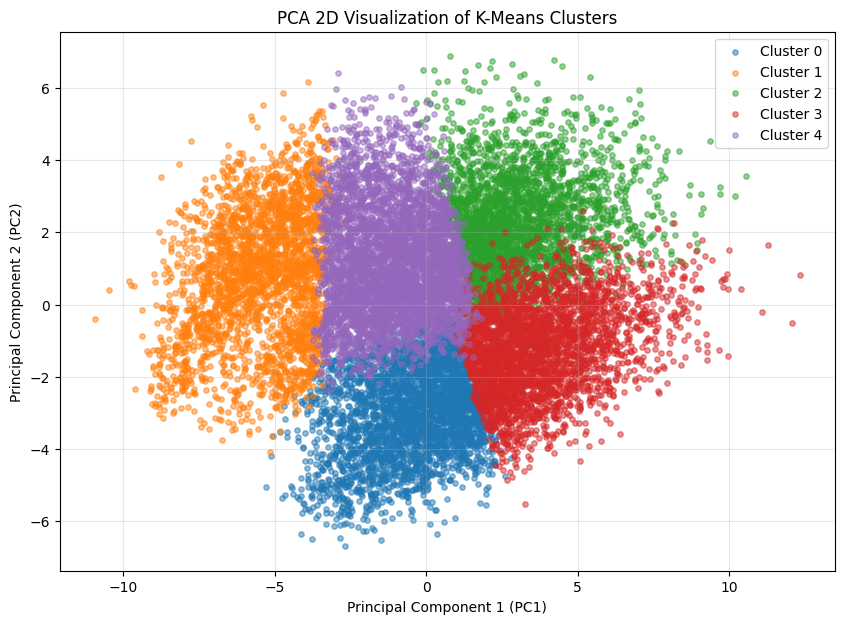

In [21]:
plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df["Cluster"].unique()):
    data = pca_df[pca_df["Cluster"] == cluster]

    plt.scatter(
        data["PC1"],
        data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=15
    )

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA 2D Visualization of K-Means Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

PCA được sử dụng để giảm không gian dữ liệu từ 30 feature xuống 2 thành phần chính nhằm trực quan hóa kết quả phân cụm K-Means. PC1 giải thích 40.32% phương sai của dữ liệu, trong khi PC2 giải thích 18.47%. Tổng hai thành phần đầu tiên giải thích 58.79% phương sai.

Kết quả cho thấy PCA 2D giữ lại một phần đáng kể thông tin biến thiên của dữ liệu và có thể được sử dụng để quan sát sự phân bố của các cluster trên mặt phẳng hai chiều. Tuy nhiên, 58.79% cũng cho thấy vẫn còn khoảng 41.21% biến thiên nằm ở các thành phần chính khác. Vì vậy, biểu đồ PCA 2D chỉ được sử dụng để minh họa trực quan, không nên dùng làm tiêu chí duy nhất để đánh giá chất lượng phân cụm. Việc đánh giá K-Means vẫn dựa trên Inertia, Silhouette Score và khả năng diễn giải của các cluster dựa trên các feature gốc.

# 11. Lập Cluster Profile bằng feature gốc

In [22]:
# Cluster Profile using original feature values

cluster_profile = (
    df_cluster
    .groupby("Cluster")[features]
    .mean()
)

pd.set_option("display.max_columns", None)

display(cluster_profile.round(2))

,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,weak_foot,skill_moves
Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,47.48,56.72,50.60,56.20,48.64,60.46,47.93,41.38,46.81,60.24,69.43,69.41,67.20,54.51,67.92,58.78,60.13,58.05,58.31,51.15,44.55,57.00,52.99,54.66,53.77,30.67,29.62,28.38,2.95,2.40
1,37.41,26.97,60.31,52.53,28.57,41.50,31.78,30.29,45.66,49.29,56.57,57.66,51.81,56.87,55.15,43.07,67.81,61.58,71.80,28.46,62.16,32.70,37.09,38.26,52.57,60.34,63.65,61.51,2.69,2.01
2,66.37,56.87,60.36,72.57,55.43,69.59,65.02,59.35,69.13,72.08,68.49,68.02,70.65,70.21,70.09,70.40,68.37,75.85,68.90,64.52,70.63,64.30,67.63,58.21,69.81,65.61,67.99,65.04,3.16,2.93
3,62.63,67.31,56.57,67.55,62.18,71.96,64.19,57.71,58.91,71.54,75.83,75.20,76.08,67.20,72.65,70.17,65.68,68.30,63.24,65.08,54.73,68.89,65.45,63.38,66.97,36.70,34.28,31.00,3.32,3.20
4,55.24,40.54,57.89,63.87,38.48,58.89,47.42,42.39,59.11,62.30,66.34,66.91,64.95,62.03,65.47,55.26,67.60,70.42,67.82,45.53,65.55,50.39,53.36,45.45,59.22,61.74,64.53,62.63,2.89,2.20


# 12 đặt tên mô tả cho từng cluster

| Cluster | Profile chính                                         | Vị trí nổi bật            | Archetype                     |
| ------- | ----------------------------------------------------- | ------------------------- | ----------------------------  |
| **0**   | Pace, acceleration, agility, kỹ thuật khá             | ST, RM, CAM, LM           | **Versatile Attacker**             |
| **1**   | Marking, tackling, strength, aggression cao           | **CB 77.31%**             | **Defensive Defender**                    |
| **2**   | Passing, ball control, vision, stamina toàn diện      | **CM 35.71%, CDM 18.29%** | **All-Round Midfielder**                   |
| **3**   | Finishing, dribbling, pace, agility, ball control cao | ST, CAM, LM, RM, LW, RW   | **Wide Attacker**        |
| **4**   | Tackling, marking, strength, stamina; kỹ thuật khá    | CB, CDM, CM, LB, RB       | **Defensive Utility Player** |



# 13 chọn 5 cầu thủ gần centroid nhất làm đại diện.

In [23]:
# Khoảng cách từ mỗi cầu thủ đến tất cả centroid
distances = kmeans_final.transform(X_scaled)

# Cluster mà mỗi cầu thủ được gán
assigned_cluster = kmeans_final.labels_

# Lấy khoảng cách đến đúng centroid của cluster đó
distance_to_centroid = distances[
    np.arange(len(X_scaled)),
    assigned_cluster
]

# Lưu khoảng cách vào dataframe
df_cluster["DistanceToCentroid"] = distance_to_centroid

# Chọn 5 cầu thủ gần centroid nhất trong mỗi cluster
top5_players = (
    df_cluster
    .sort_values(["Cluster", "DistanceToCentroid"])
    .groupby("Cluster")
    .head(5)
)

# Hiển thị
display(
    top5_players[
        [
            "sofifa_id",
            "short_name",
            "player_positions",
            "Cluster",
            "DistanceToCentroid"
        ]
    ]
)

,sofifa_id,short_name,player_positions,Cluster,DistanceToCentroid
15512,251356,N. Vallys,"LM, CAM, RM",0,1.899650
15235,245522,H. Al Maqati,"RM, CAM, ST",0,1.978398
14637,247507,P. Glatzel,ST,0,1.996262
16619,252879,Z. Issaka,RM,0,2.024710
14638,248228,V. De Baunbag,"ST, RW",0,2.073849
13590,251886,A. Frías,CB,1,1.644946
11220,209232,L. Šatka,"CB, RB",1,1.694688
11194,240021,Pelayo Suárez,CB,1,1.743174
12314,239502,W. Bianda,CB,1,1.754667
13965,250905,K. Velkov,CB,1,1.758659


# 14 đối chiếu với player_positions để xem mỗi cụm thường gồm những vị trí nào.

In [24]:
df_cluster["primary_position"] = (
    df_cluster["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

position_profile = (
    pd.crosstab(
        df_cluster["Cluster"],
        df_cluster["primary_position"],
        normalize="index"
    ) * 100
)

display(position_profile.round(2))

primary_position,CAM,CB,CDM,CF,CM,LB,LM,LW,LWB,RB,RM,RW,RWB,ST
Cluster,,,,,,,,,,,,,,
0,12.38,0.00,0.27,1.22,8.78,0.64,11.55,4.48,0.12,0.61,12.80,4.79,0.12,42.23
1,0.00,77.31,4.56,0.00,2.00,7.30,0.19,0.04,0.52,7.53,0.15,0.00,0.26,0.15
2,5.25,5.12,18.29,0.28,35.71,13.10,2.90,0.35,0.80,11.79,3.42,0.41,0.66,1.94
3,16.79,0.00,0.00,1.93,4.50,0.06,15.94,6.61,0.03,0.12,13.98,5.90,0.03,34.11
4,0.95,22.64,18.60,0.05,16.35,17.16,1.46,0.10,1.17,18.18,1.71,0.17,0.93,0.54


C0 ST 42.23%, nhưng cũng có CAM 12.38%, LM 11.55%, RM 12.80%

C1 CB chiếm tới 77.31%

C2 CM 35.71% + CDM 18.29%

C3 ST 34.11%

C4 CB, LB, RB, CM, CDM đều chiếm tỷ trọng đáng kể

# 15 Tạo ClusterName + xuất file player_archetypes.csv.

In [25]:
cluster_names = {
    0: "Versatile Attacker",
    1: "Defensive Defender",
    2: "All-Round Midfielder",
    3: "Wide Attacker",
    4: "Defensive Utility Player"
}

df_cluster["ClusterName"] = df_cluster["Cluster"].map(cluster_names)

In [26]:
output_cols = [
    "sofifa_id",
    "short_name",
    "player_positions",
    "Cluster",
    "ClusterName",
    "DistanceToCentroid"
]

player_archetypes = df_cluster[output_cols].copy()

player_archetypes.to_csv(
    "player_archetypes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất: player_archetypes.csv")
print("Số cầu thủ:", len(player_archetypes))

display(player_archetypes.head(10))

Đã xuất: player_archetypes.csv
Số cầu thủ: 16242


,sofifa_id,short_name,player_positions,Cluster,ClusterName,DistanceToCentroid
0,158023,L. Messi,"RW, CF, ST",3,Wide Attacker,9.308503
1,20801,Cristiano Ronaldo,"ST, LW",3,Wide Attacker,9.262809
2,190871,Neymar Jr,"LW, CAM",3,Wide Attacker,9.103678
4,183277,E. Hazard,"LW, CF",3,Wide Attacker,7.961894
5,192985,K. De Bruyne,"CAM, CM",2,All-Round Midfielder,8.144301
7,203376,V. van Dijk,CB,2,All-Round Midfielder,6.035539
8,177003,L. Modrić,CM,2,All-Round Midfielder,7.309640
9,209331,M. Salah,"RW, ST",3,Wide Attacker,7.120312
10,231747,K. Mbappé,"ST, RW",3,Wide Attacker,7.300700
11,201024,K. Koulibaly,CB,4,Defensive Utility Player,7.417288


# BÁO CÁO PLAYER ARCHETYPE CLUSTERING – FIFA 20

## 1. Mục tiêu

Mục tiêu của bài toán là phân nhóm các cầu thủ bóng đá trong FIFA 20 thành những nhóm có đặc điểm kỹ năng và thể chất tương đồng, từ đó xây dựng các **Player Archetype** có khả năng diễn giải về mặt chuyên môn. Bài toán chỉ sử dụng các cầu thủ ngoài vị trí thủ môn và không sử dụng các thông tin định danh hoặc thông tin tổng hợp như `sofifa_id`, tên cầu thủ, câu lạc bộ, quốc tịch, `overall`, `potential`, `value` và `wage` làm đặc trưng chính cho quá trình clustering.

## 2. Lựa chọn đặc trưng và tiền xử lý

Tổng cộng **30 đặc trưng** được lựa chọn từ các nhóm Attacking, Skill, Movement, Physical/Power, Mentality, Defending và General Skills. Các đặc trưng này bao gồm khả năng dứt điểm, chuyền bóng, rê bóng, kiểm soát bóng, tốc độ, khả năng tăng tốc, sự nhanh nhẹn, sức mạnh, thể lực, phòng ngự và các yếu tố tâm lý thi đấu.

Việc lựa chọn các đặc trưng này nhằm mô tả trực tiếp năng lực thi đấu của cầu thủ thay vì dựa vào một chỉ số tổng hợp. Trước khi áp dụng K-Means và DBSCAN, dữ liệu được chuẩn hóa bằng **StandardScaler**. Bước scaling là cần thiết vì các thuật toán dựa trên khoảng cách, đặc biệt là K-Means và DBSCAN, có thể bị ảnh hưởng nếu các đặc trưng có thang đo khác nhau.

## 3. K-Means và lựa chọn số cluster

K-Means được chạy với các giá trị `k` từ **3 đến 10**. Kết quả cho thấy inertia giảm liên tục khi tăng số cluster, từ **308491.81 ở k=3** xuống **212383.51 ở k=10**. Đây là xu hướng thông thường của K-Means vì số cluster tăng sẽ giúp các điểm dữ liệu gần centroid của cluster hơn.

Silhouette Score đạt giá trị cao nhất tại **k=3 với 0.187511**. Tuy nhiên, khi xem xét mục tiêu xây dựng các archetype cầu thủ, chỉ sử dụng một metric để lựa chọn k là chưa đủ. Với k=3, các nhóm có thể quá rộng và gộp nhiều kiểu cầu thủ khác nhau vào cùng một cluster. Vì vậy, **k=5 được lựa chọn cho clustering cuối cùng**, nhằm tạo ra các nhóm có mức độ chi tiết cao hơn và dễ diễn giải hơn về mặt chuyên môn.

Kết quả cuối cùng tạo ra 5 cluster, được đặt tên dựa trên profile kỹ năng và vị trí cầu thủ.

## 4. Phân tích các Player Archetype

**Cluster 0 – Versatile Attacker:** Nhóm này nổi bật về acceleration, sprint speed, agility cùng với dribbling và ball control ở mức khá. Các cầu thủ đại diện có những vị trí như LM, RM, CAM, ST và RW, cho thấy khả năng hoạt động ở nhiều vị trí tấn công. Một số cầu thủ gần centroid gồm N. Vallys, H. Al Maqati và P. Glatzel.

**Cluster 1 – Defensive Defender:** Đây là nhóm có đặc điểm phòng ngự rõ ràng, với marking, standing tackle, sliding tackle và strength cao, trong khi finishing thấp. Các cầu thủ gần centroid chủ yếu chơi CB như A. Frías, Pelayo Suárez, W. Bianda và K. Velkov. Vì vậy cluster này được xác định là nhóm hậu vệ thiên về phòng ngự.

**Cluster 2 – All-Round Midfielder:** Cluster này có profile toàn diện về short passing, long passing, ball control, dribbling, vision và stamina. Các vị trí của những cầu thủ gần centroid chủ yếu nằm ở CM, CDM và CAM, chẳng hạn G. Cimirot, S. Branca và C. Donis. Đây là nhóm tiền vệ có khả năng tham gia nhiều nhiệm vụ khác nhau.

**Cluster 3 – Wide Attacker:** Nhóm này nổi bật về finishing, dribbling, acceleration, sprint speed, agility và ball control. Các vị trí LW, LM, RM và RW xuất hiện nhiều trong nhóm đại diện, cùng với một số cầu thủ có thể chơi ST. Những cầu thủ như H. Toledo, D. Sallói và T. Chancalay minh họa cho kiểu cầu thủ tấn công thiên về tốc độ và kỹ thuật ở khu vực biên.

**Cluster 4 – Defensive Utility Player:** Cluster này có tackling, marking, strength và stamina khá cao, đồng thời short passing cũng tương đối tốt. Các cầu thủ gần centroid chủ yếu chơi CDM hoặc CM, bên cạnh một số vị trí như RB/RWB. A. Hazazi, A. Al Khaibari và T. Børkeeiet là những đại diện tiêu biểu. Nhóm này có đặc điểm phòng ngự nhưng có khả năng đảm nhiệm nhiều vị trí.

## 5. DBSCAN

DBSCAN được thử nghiệm với bốn cấu hình. Với `eps=2.0, min_samples=5`, thuật toán tạo 40 cluster nhưng có tới **92.75% dữ liệu bị xem là noise**. Khi tăng `eps` lên 2.5, số cluster giảm xuống 7 nhưng noise vẫn chiếm **49.60%**. Với `eps=3.0, min_samples=5`, chỉ còn 2 cluster và noise giảm xuống **13.98%**. Cấu hình `eps=2.5, min_samples=10` tạo 1 cluster và **56.05% noise**.

Kết quả cho thấy DBSCAN khá nhạy với việc lựa chọn tham số trên dữ liệu cầu thủ đã chuẩn hóa. Vì vậy, K-Means với k=5 được sử dụng làm kết quả clustering chính, còn DBSCAN được dùng như một phương pháp đối chiếu.

## 6. PCA và kết luận

PCA 2 chiều cho thấy **PC1 giải thích 40.32%** phương sai và **PC2 giải thích 18.47%**, tổng cộng **58.79%**. PCA được sử dụng chủ yếu để trực quan hóa cấu trúc cluster trong không gian 2D; chất lượng clustering không được đánh giá chỉ dựa trên biểu đồ PCA vì vẫn còn 41.21% phương sai nằm ở các thành phần khác.

Nhìn chung, quá trình clustering đã kết hợp giữa metric định lượng, profile kỹ năng và thông tin vị trí để xây dựng 5 Player Archetype: **Versatile Attacker, Defensive Defender, All-Round Midfielder, Wide Attacker và Defensive Utility Player**. Cách tiếp cận này giúp các cluster không chỉ có ý nghĩa về mặt toán học mà còn có khả năng diễn giải theo vai trò thi đấu của cầu thủ.
